In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [98]:
df = pd.read_csv("/content/cardio_data.csv", sep = ";")

In [99]:
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [101]:
df.isnull().sum()

,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


In [102]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [103]:
# The id column is only a number for each patient – it does not help prediction
df.drop(columns='id', inplace=True)

In [104]:
df

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1


In [105]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 24


In [106]:
df.drop_duplicates(inplace=True)

In [107]:
df

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1


In [108]:
# Convert age from days to years
df['age_years'] = (df['age'] / 365.25).round(1)
df[['age', 'age_years']].head()

,age,age_years
0,18393,50.4
1,20228,55.4
2,18857,51.6
3,17623,48.2
4,17474,47.8


In [109]:
df

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.4
1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.4
2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51.6
3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.2
4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0,52.7
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1,61.9
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1,52.2
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1,61.4


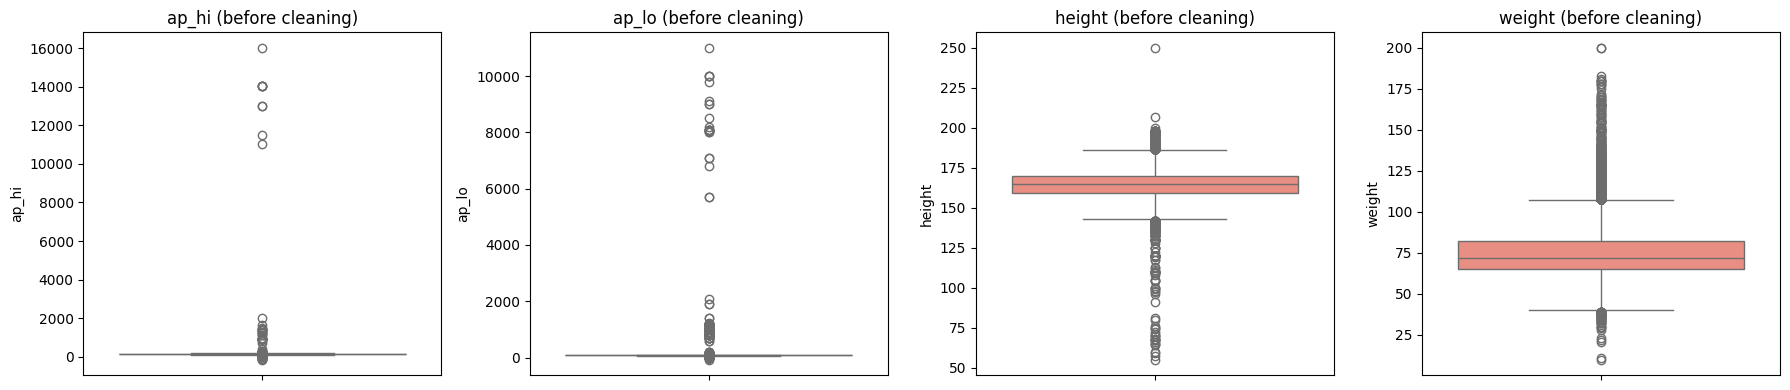

In [110]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, ['ap_hi', 'ap_lo', 'height', 'weight']):
    sns.boxplot(y=df[col], ax=ax, color='salmon')
    ax.set_title(col + ' (before cleaning)')

plt.tight_layout()
plt.show()

In [111]:
print(df['ap_hi'].sort_values().head(10))
print(df['ap_hi'].sort_values(ascending=False).head(10))

print(df['ap_lo'].sort_values().head(10))
print(df['ap_lo'].sort_values(ascending=False).head(10))

35040   -150
23988   -140
25240   -120
46627   -120
16021   -115
4607    -100
20536   -100
8757       1
42334      1
5382       7
Name: ap_hi, dtype: int64
40852    16020
25464    14020
46912    14020
25519    14020
47253    14020
55459    13010
55847    13010
7763     11500
51438    11020
69370     2000
Name: ap_hi, dtype: int64
60106   -70
68663     0
41505     0
40330     0
38370     0
42397     0
63787     0
52580     0
2014      0
27686     0
Name: ap_lo, dtype: int64
43326    11000
2381     10000
23849    10000
68538    10000
43434     9800
6653      9100
12086     9011
32920     9011
15990     8500
44042     8200
Name: ap_lo, dtype: int64


In [112]:
# Count invalid or suspicious blood pressure values
print("Systolic below 80:", (df['ap_hi'] < 80).sum())
print("Diastolic below 40:", (df['ap_lo'] < 40).sum())
print("Systolic above 250:", (df['ap_hi'] > 250).sum())
print("Diastolic above 200:", (df['ap_lo'] > 200).sum())
print("Systolic <= diastolic:", (df['ap_hi'] <= df['ap_lo']).sum())

Systolic below 80: 207
Diastolic below 40: 59
Systolic above 250: 40
Diastolic above 200: 953
Systolic <= diastolic: 1236


In [113]:
# Find suspicious blood pressure records
suspicious_bp = df[
    (df['ap_hi'] < 80) |
    (df['ap_lo'] < 40) |
    (df['ap_hi'] > 250) |
    (df['ap_lo'] > 200) |
    (df['ap_hi'] <= df['ap_lo'])
]

print("Suspicious records:", len(suspicious_bp))

suspicious_bp[['ap_hi', 'ap_lo', 'cardio']].head(20)

Suspicious records: 1333


,ap_hi,ap_lo,cardio
228,160,1100,1
241,160,1000,1
260,140,800,1
329,160,1000,1
345,140,1000,1
418,150,30,1
473,150,1033,1
474,120,150,0
559,200,1000,1
567,14,90,1


In [114]:
# Create a copy of the original dataset
df_clean = df.copy()

# Define screening rules
valid_bp = (
    (df_clean['ap_hi'] >= 80) &
    (df_clean['ap_hi'] <= 250) &
    (df_clean['ap_lo'] >= 40) &
    (df_clean['ap_lo'] <= 200) &
    (df_clean['ap_hi'] > df_clean['ap_lo'])
)

# Keep records that pass the screening rules
df_clean = df_clean[valid_bp].copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Records removed:", len(df) - len(df_clean))

Original dataset shape: (69976, 13)
Cleaned dataset shape: (68643, 13)
Records removed: 1333


In [115]:
df_clean

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.4
1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.4
2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51.6
3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.2
4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0,52.7
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1,61.9
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1,52.2
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1,61.4


In [116]:
print(df_clean.isnull().sum())

age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
age_years      0
dtype: int64


In [117]:
print("Height - lowest values:")
print(df_clean['height'].sort_values().head(10))

print("\nHeight - highest values:")
print(df_clean['height'].sort_values(ascending=False).head(10))

print("\nWeight - lowest values:")
print(df_clean['weight'].sort_values().head(10))

print("\nWeight - highest values:")
print(df_clean['weight'].sort_values(ascending=False).head(10))

Height - lowest values:
22723    55
66643    57
64115    59
29157    60
27603    64
33607    65
44490    65
53344    67
50789    67
14323    67
Name: height, dtype: int64

Height - highest values:
6486     250
21628    207
40090    198
50212    198
39351    198
29145    198
8897     198
66145    198
1117     198
57529    198
Name: height, dtype: int64

Weight - lowest values:
33817    11.0
60188    21.0
29488    22.0
26806    23.0
34276    28.0
60699    29.0
18559    30.0
3752     30.0
41905    30.0
16906    31.0
Name: weight, dtype: float64

Weight - highest values:
435      200.0
50413    200.0
61285    183.0
61362    180.0
45378    180.0
4743     180.0
60592    180.0
27384    178.0
20092    178.0
61788    178.0
Name: weight, dtype: float64


In [118]:
# Count suspicious height values
print("Height below 120 cm:", (df_clean['height'] < 120).sum())

print("Height above 220 cm:", (df_clean['height'] > 220).sum())

print("Weight below 30 kg:", (df_clean['weight'] < 30).sum())

print("Weight above 250 kg:", (df_clean['weight'] > 250).sum())

Height below 120 cm: 49
Height above 220 cm: 1
Weight below 30 kg: 6
Weight above 250 kg: 0


In [119]:
suspicious_hw = df_clean[
    (df_clean['height'] < 120) |
    (df_clean['height'] > 220) |
    (df_clean['weight'] < 30) |
    (df_clean['weight'] > 250)
]

print("Suspicious height/weight records:", len(suspicious_hw))
suspicious_hw[['age_years', 'gender', 'height', 'weight', 'cardio']].sort_values(by='height')

Suspicious height/weight records: 56


,age_years,gender,height,weight,cardio
22723,64.0,1,55,81.0,1
66643,51.6,1,57,61.0,1
64115,50.4,1,59,57.6,0
29157,52.3,1,60,69.0,0
27603,57.4,1,64,61.0,0
44490,52.3,1,65,60.0,0
33607,54.0,2,65,72.0,0
14323,60.2,1,67,57.0,1
50789,39.7,2,67,60.0,0
53344,56.2,2,67,80.0,1


In [120]:
# Keep a record of the dataset before height/weight cleaning
df_before_hw = df_clean.copy()

valid_hw = (
    (df_clean['height'] >= 120) &
    (df_clean['height'] <= 220) &
    (df_clean['weight'] >= 30) &
    (df_clean['weight'] <= 250)
)

# Apply cleaning
df_clean = df_clean[valid_hw].copy()

# Display results
print("Before height/weight cleaning:", df_before_hw.shape)
print("After height/weight cleaning:", df_clean.shape)
print("Records removed:", len(df_before_hw) - len(df_clean))

Before height/weight cleaning: (68643, 13)
After height/weight cleaning: (68587, 13)
Records removed: 56


In [121]:
# BMI = weight (kg) / height (m)^2
df_clean['bmi'] = (df_clean['weight'] / (df_clean['height'] / 100) ** 2).round(2)
df_clean[['height', 'weight', 'bmi']].head()

,height,weight,bmi
0,168,62.0,21.97
1,156,85.0,34.93
2,165,64.0,23.51
3,169,82.0,28.71
4,156,56.0,23.01


In [122]:
print(df_clean['bmi'].describe())

count    68587.000000
mean        27.458967
std          5.257271
min         10.730000
25%         23.880000
50%         26.350000
75%         30.120000
max        108.170000
Name: bmi, dtype: float64


In [123]:

print("BMI below 12:", (df_clean['bmi'] < 12).sum())
print("BMI above 50:", (df_clean['bmi'] > 50).sum())

BMI below 12: 2
BMI above 50: 186


In [124]:
df_clean.nsmallest(10, 'bmi')[['age_years', 'gender', 'height', 'weight', 'bmi', 'cardio']]

,age_years,gender,height,weight,bmi,cardio
16906,47.3,2,170,31.0,10.73,1
18559,49.7,1,160,30.0,11.72,1
58200,61.7,1,169,35.0,12.25,1
16322,59.9,1,165,35.0,12.86,0
38417,59.7,1,154,32.0,13.49,0
9487,57.4,2,172,40.0,13.52,1
10447,60.3,1,162,38.0,14.48,0
33511,57.7,1,153,34.0,14.52,1
32608,52.0,1,176,45.0,14.53,1
16225,53.7,1,196,56.0,14.58,0


In [125]:
df_clean = df_clean[df_clean['bmi'] >= 12]

# BMI below 12 is not realistic; BMI above 50 is possible (severe obesity), so kept
print("Final cleaned dataset shape:", df_clean.shape)
print("Total records removed:", len(df) - len(df_clean))

Final cleaned dataset shape: (68585, 14)
Total records removed: 1391


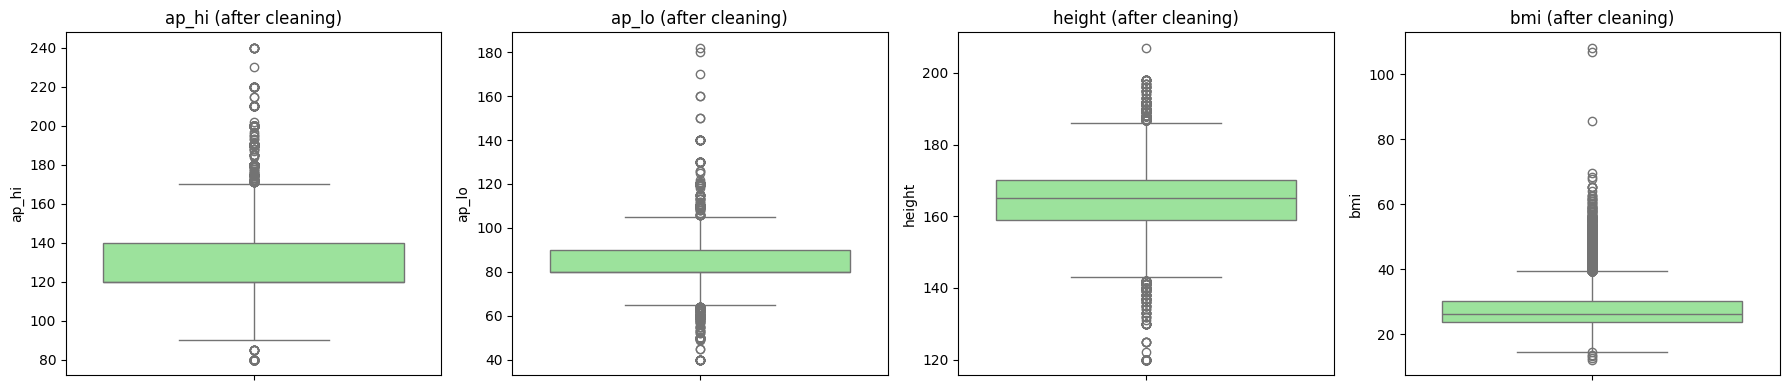

In [126]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, ['ap_hi', 'ap_lo', 'height', 'bmi']):
    sns.boxplot(y=df_clean[col], ax=ax, color='lightgreen')
    ax.set_title(col + ' (after cleaning)')

plt.tight_layout()
plt.show()

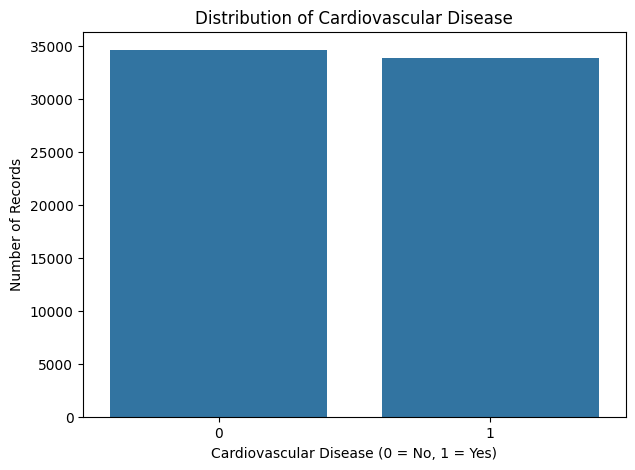

In [127]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x='cardio')
plt.title('Distribution of Cardiovascular Disease')
plt.xlabel('Cardiovascular Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.show()

In [128]:
print(df_clean['cardio'].value_counts())
print(df_clean['cardio'].value_counts(normalize=True) * 100)

cardio
0    34649
1    33936
Name: count, dtype: int64
cardio
0    50.519793
1    49.480207
Name: proportion, dtype: float64


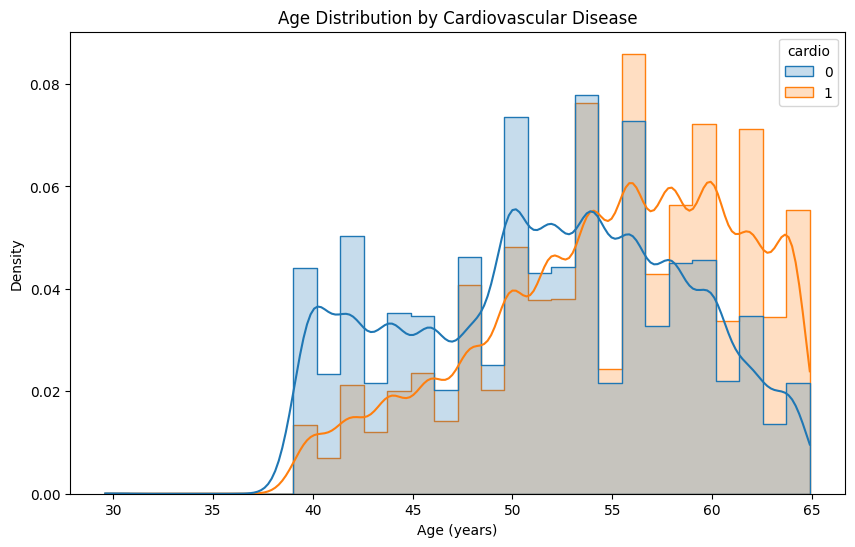

In [129]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='age_years', hue='cardio', bins=30, kde=True,
             element='step', stat='density', common_norm=False)
plt.title('Age Distribution by Cardiovascular Disease')
plt.xlabel('Age (years)')
plt.ylabel('Density')
plt.show()

In [130]:
df_clean['age_group'] = pd.cut(df_clean['age_years'], bins=[29, 40, 45, 50, 55, 60, 66],
                               labels=['30-40', '40-45', '45-50', '50-55', '55-60', '60-65'])

/tmp/ipykernel_664/2766685966.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disease_rate = df_clean.groupby('age_group')['cardio'].mean() * 100


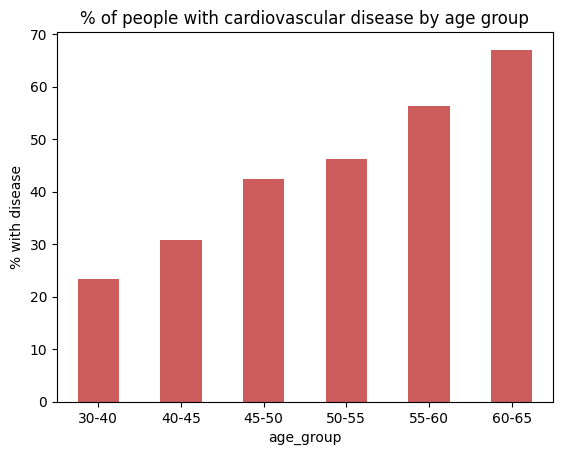

age_group
30-40    23.4
40-45    30.8
45-50    42.5
50-55    46.2
55-60    56.2
60-65    67.1
Name: cardio, dtype: float64


In [131]:
disease_rate = df_clean.groupby('age_group')['cardio'].mean() * 100
disease_rate.plot(kind='bar', color='indianred')
plt.title('% of people with cardiovascular disease by age group')
plt.ylabel('% with disease')
plt.xticks(rotation=0)
plt.show()
print(disease_rate.round(1))

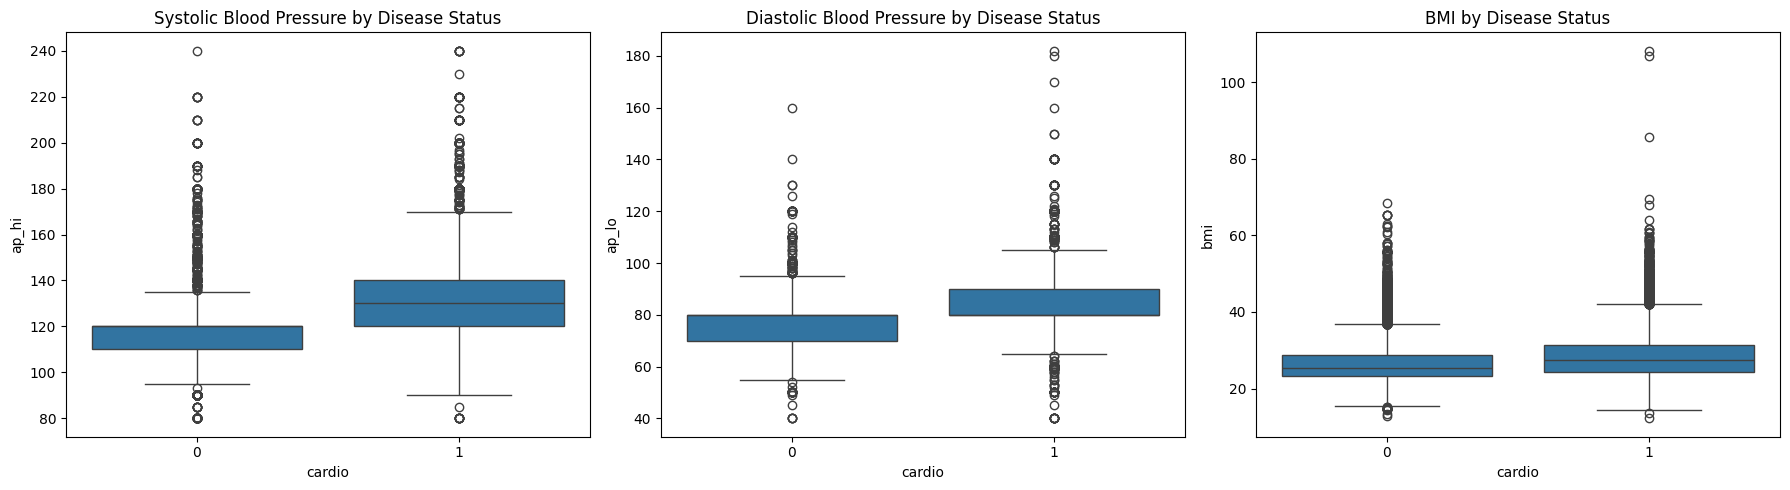

In [132]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_clean, x='cardio', y='ap_hi', ax=axes[0])
axes[0].set_title('Systolic Blood Pressure by Disease Status')

sns.boxplot(data=df_clean, x='cardio', y='ap_lo', ax=axes[1])
axes[1].set_title('Diastolic Blood Pressure by Disease Status')

sns.boxplot(data=df_clean, x='cardio', y='bmi', ax=axes[2])
axes[2].set_title('BMI by Disease Status')

plt.tight_layout()
plt.show()

In [133]:
# High blood pressure = 140/90 or more
df_clean['high_bp'] = ((df_clean['ap_hi'] >= 140) | (df_clean['ap_lo'] >= 90)).astype(int)
print((df_clean.groupby('high_bp')['cardio'].mean() * 100).round(1))

high_bp
0    34.6
1    78.0
Name: cardio, dtype: float64


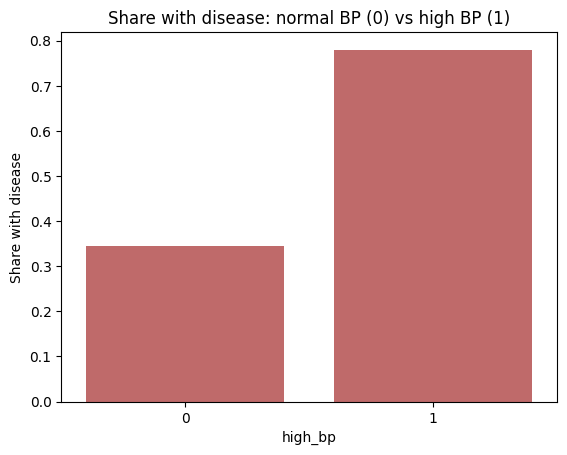

In [134]:
sns.barplot(data=df_clean, x='high_bp', y='cardio', errorbar=None, color='indianred')
plt.title('Share with disease: normal BP (0) vs high BP (1)')
plt.ylabel('Share with disease')
plt.show()

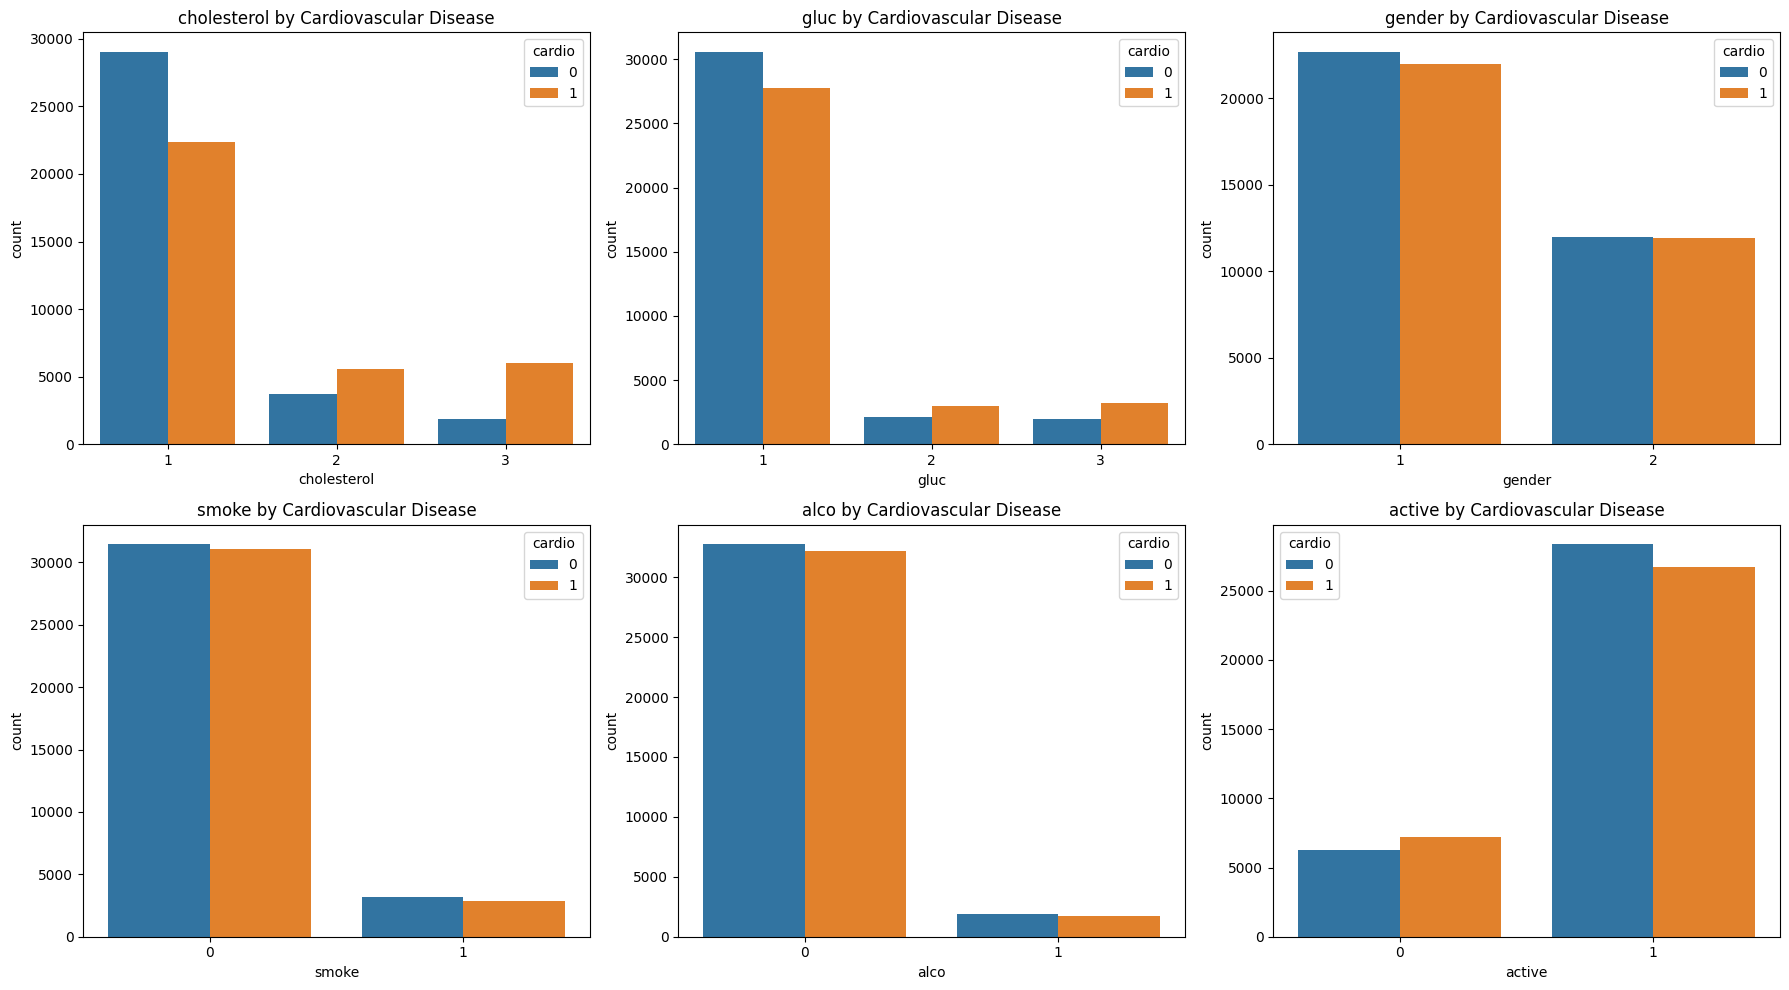

In [135]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, col in zip(axes.flatten(), ['cholesterol', 'gluc', 'gender', 'smoke', 'alco', 'active']):
    sns.countplot(data=df_clean, x=col, hue='cardio', ax=ax)
    ax.set_title(col + ' by Cardiovascular Disease')

plt.tight_layout()
plt.show()

In [136]:
# % of people with the disease in each category
for col in ['cholesterol', 'gluc', 'gender', 'smoke', 'alco', 'active']:
    print(col, (df_clean.groupby(col)['cardio'].mean() * 100).round(1).to_dict())

cholesterol {1: 43.5, 2: 59.6, 3: 76.2}
gluc {1: 47.6, 2: 58.9, 3: 61.8}
gender {1: 49.2, 2: 50.0}
smoke {0: 49.7, 1: 46.8}
alco {0: 49.6, 1: 47.7}
active {0: 53.3, 1: 48.5}


In [137]:
features = ['age_years', 'gender', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo',
            'cholesterol', 'gluc', 'smoke', 'alco', 'active']

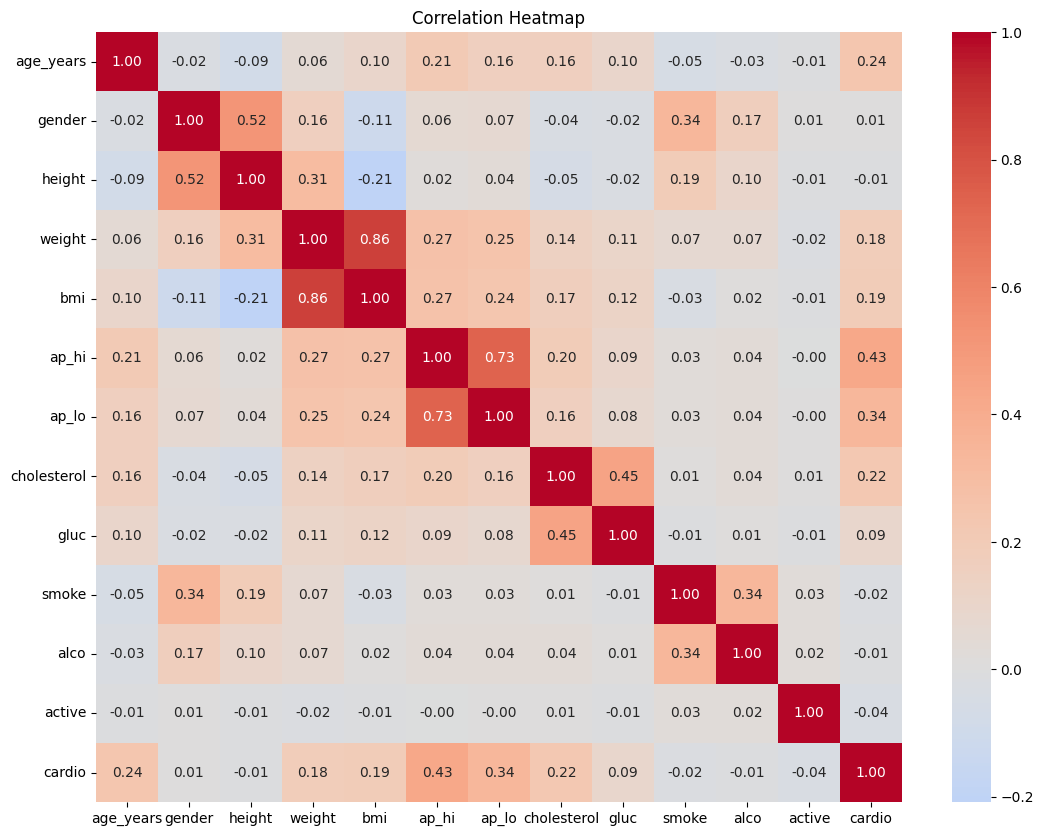

In [138]:
plt.figure(figsize=(13, 10))
sns.heatmap(df_clean[features + ['cardio']].corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Heatmap')
plt.show()

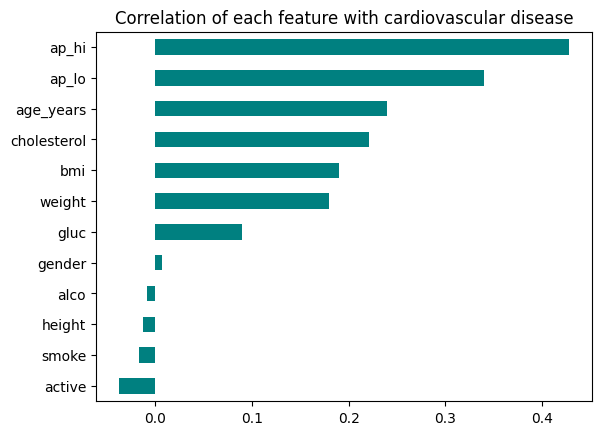

In [139]:
df_clean[features].corrwith(df_clean['cardio']).sort_values().plot(kind='barh', color='teal')
plt.title('Correlation of each feature with cardiovascular disease')
plt.show()

In [140]:
x = df_clean[features]
y = df_clean['cardio']

In [141]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [142]:
print(len(x_train))
print(len(x_test))

54868
13717


In [143]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

In [144]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [145]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=35),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    'SVM': SVC()
}

In [146]:
results = []
for name, model in models.items():
    model.fit(x_train_s, y_train)
    acc = model.score(x_test_s, y_test)
    results.append([name, round(acc * 100, 2)])
    print(name, ':', round(acc * 100, 2), '%')

results = pd.DataFrame(results, columns=['Model', 'Accuracy (%)']).sort_values('Accuracy (%)', ascending=False)
results

Logistic Regression : 72.65 %
KNN : 72.77 %
Decision Tree : 73.16 %
Random Forest : 73.41 %
SVM : 73.27 %


,Model,Accuracy (%)
3,Random Forest,73.41
4,SVM,73.27
2,Decision Tree,73.16
1,KNN,72.77
0,Logistic Regression,72.65


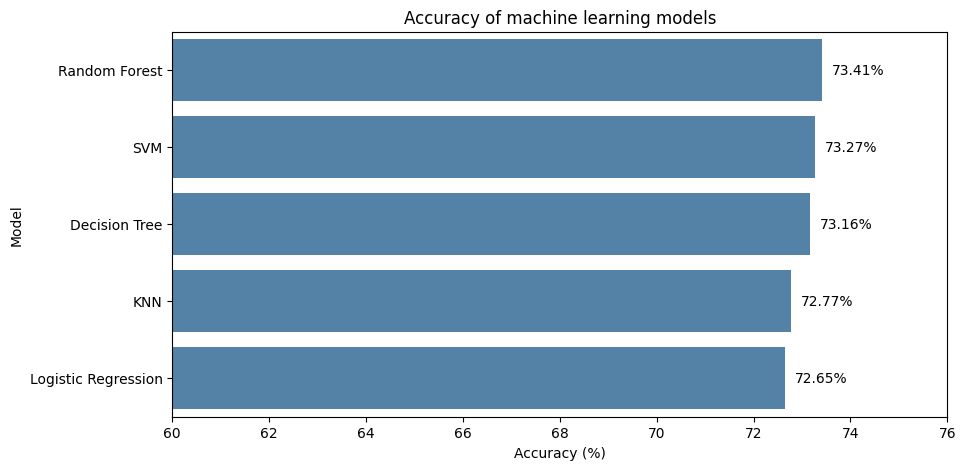

In [147]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results, x='Accuracy (%)', y='Model', color='steelblue')
for i, v in enumerate(results['Accuracy (%)']):
    ax.text(v + 0.2, i, str(v) + '%', va='center')
plt.xlim(60, 76)
plt.title('Accuracy of machine learning models')
plt.show()

In [148]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf_model.fit(x_train_s, y_train)

RandomForestClassifier(max_depth=8, n_estimators=200, random_state=42)

In [149]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

ans = rf_model.predict(x_test_s)

print('Accuracy :', round(accuracy_score(y_test, ans) * 100, 2), '%')
print(classification_report(y_test, ans, target_names=['No disease', 'Disease']))

Accuracy : 73.41 %
              precision    recall  f1-score   support

  No disease       0.71      0.79      0.75      6930
     Disease       0.76      0.68      0.72      6787

    accuracy                           0.73     13717
   macro avg       0.74      0.73      0.73     13717
weighted avg       0.74      0.73      0.73     13717



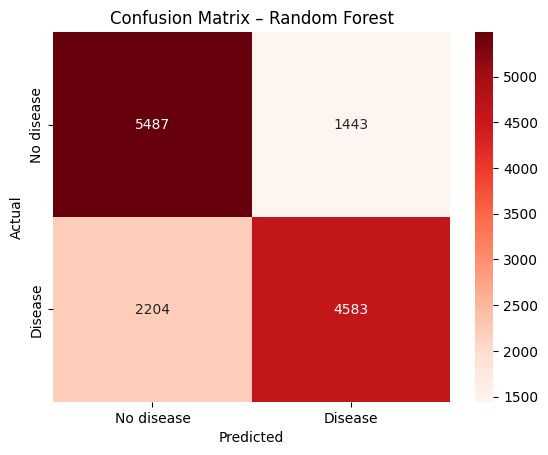

In [150]:
cm = confusion_matrix(y_test, ans)

sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['No disease', 'Disease'],
            yticklabels=['No disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix – Random Forest')
plt.show()

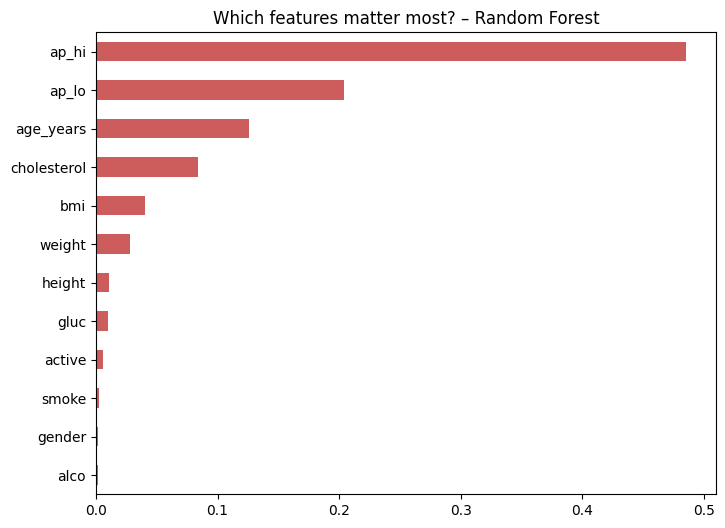

In [151]:
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values()
importance.plot(kind='barh', color='indianred', figsize=(8, 6))
plt.title('Which features matter most? – Random Forest')
plt.show()

In [152]:
def predict_person(age, gender, height, weight, ap_hi, ap_lo, cholesterol, gluc, smoke, alco, active):
    bmi = weight / (height / 100) ** 2
    person = pd.DataFrame([[age, gender, height, weight, bmi, ap_hi, ap_lo,
                            cholesterol, gluc, smoke, alco, active]], columns=features)
    person_s = scaler.transform(person)
    result = rf_model.predict(person_s)[0]
    chance = rf_model.predict_proba(person_s)[0][1] * 100
    if result == 1:
        print('Cardiovascular disease: YES  (probability', round(chance, 1), '%)')
    else:
        print('Cardiovascular disease: NO   (probability', round(chance, 1), '%)')

predict_person(age=58, gender=2, height=172, weight=92, ap_hi=160, ap_lo=100,
               cholesterol=3, gluc=1, smoke=1, alco=0, active=0)

predict_person(age=35, gender=1, height=165, weight=58, ap_hi=115, ap_lo=75,
               cholesterol=1, gluc=1, smoke=0, alco=0, active=1)

Cardiovascular disease: YES  (probability 83.5 %)
Cardiovascular disease: NO   (probability 12.3 %)


Random Forest gave the highest accuracy (73.41%), so it was chosen as the final model. Blood pressure, age and cholesterol are the most important predictors of heart disease.